# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
import scipy.cluster.hierarchy as sch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# you will need to import more libraries as needed

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [130]:
customer_data = pd.read_csv('shopping-data.csv')

In [131]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [132]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

<function matplotlib.pyplot.show(close=None, block=None)>

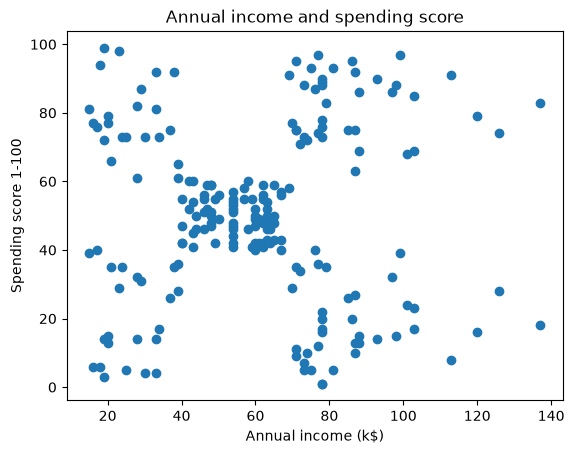

In [133]:
X = customer_data.iloc[:, [3, 4]].values
plt.scatter(X[:, 0], X[:, 1])
plt.title("Annual income and spending score")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score 1-100")
plt.show

#### 3. Normalize the data

In [134]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) 

#### 4. Use Elbow method to decide number of clusters

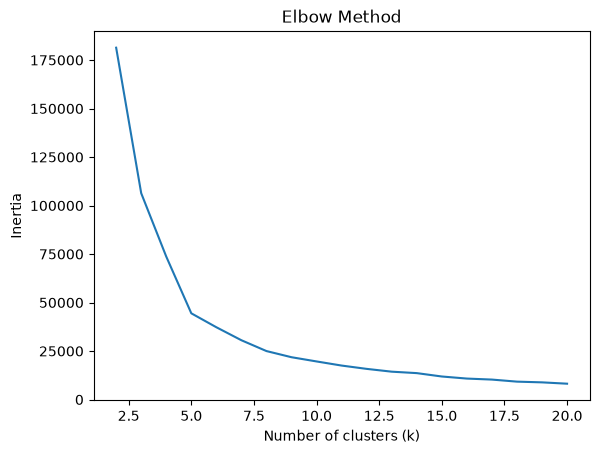

In [135]:
elbow=[]
for i in range(2, 21):
    kmeans = KMeans(n_clusters = i, init='k-means++', n_init=10, random_state = 555, max_iter = 200) # read from the internet that setting from init='k-mean++' to n_init=10 makes the result more stable so i am going to leave that way
    kmeans.fit(X)
    elbow.append(kmeans.inertia_)

plt.plot(range(2, 21), elbow)
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

#### 5. Perform Clustering using KMeans

In [136]:
kmeans = KMeans(n_clusters = 5, init='k-means++', n_init = 10, random_state = 42)
y_kmeans = kmeans.fit_predict(X)

#### 6. Plot scatter plot and color code in clustered groups

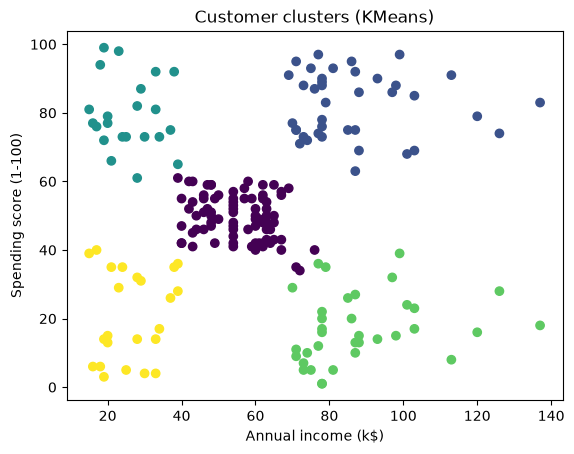

In [137]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis')
plt.title("Customer clusters (KMeans)")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1-100)")
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

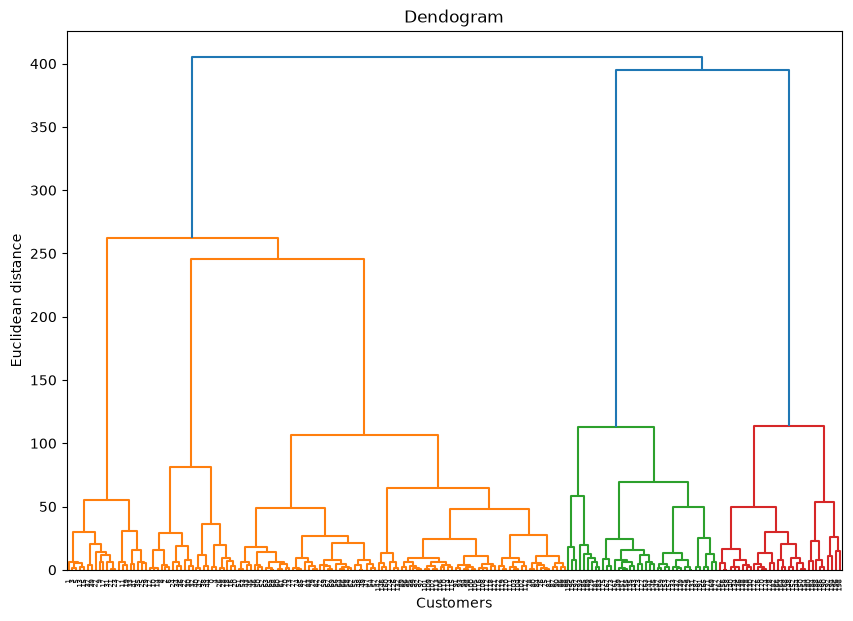

In [138]:
plt.figure(figsize=(10, 7))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title("Dendogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean distance")
plt.show()

Looking at the dendrogram the optimal number for clusters is 5. The longest vertical distance that is not crossed by any horizontal line lies between the 4-cluster and 5-cluster merges. Merging beyond this point would join clusters with a large distance between them, so 5 is the natural number of groups. Also this agrees with elbow method and the scatter plot.

#### 8. Do clustering using Hierarchical Clustering

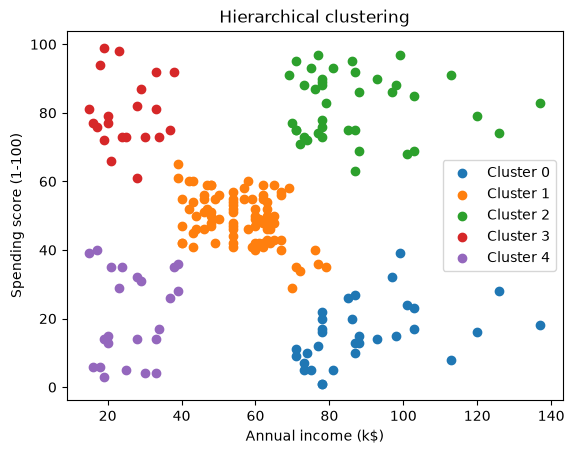

In [139]:
n_clusters = 5
hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

for i in range(n_clusters):
    plt.scatter(X[y_hc == i, 0], X[y_hc == i, 1], label=f"Cluster {i}")

plt.title("Hierarchical clustering")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1-100)")
plt.legend()
plt.show()

#### 9. Plot scatter plot and color code in clustered groups

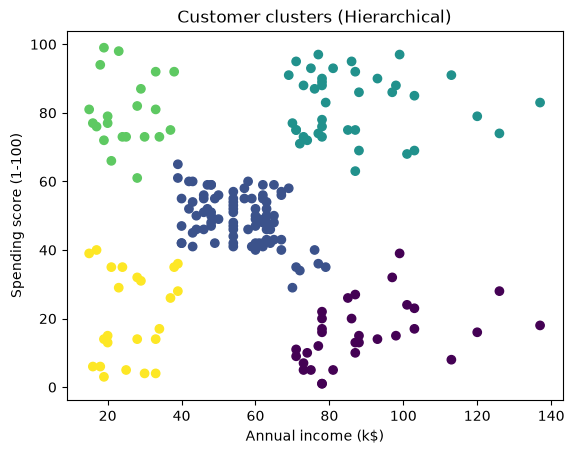

In [140]:
plt.scatter(X[:, 0], X[:, 1], c=y_hc, cmap='viridis')
plt.title("Customer clusters (Hierarchical)")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score (1-100)")
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [141]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)


Preparing KMeans with 2 clusters and DBSCAN

In [142]:
km_moons = KMeans(n_clusters=2, n_init=10, random_state=42)
km_labels = km_moons.fit_predict(moons_X)

db = DBSCAN(eps = 0.2, min_samples = 5)
db_labels = db.fit_predict(moons_X)

Plot figures

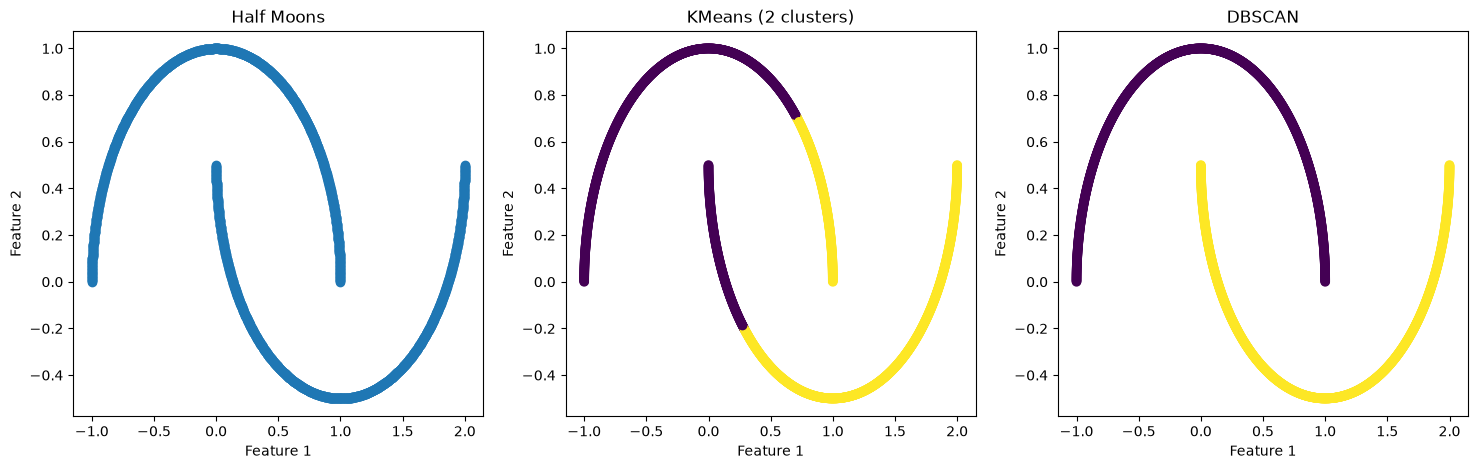

In [143]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(moons_X[:, 0], moons_X[:, 1])
axes[0].set_title('Half Moons')

axes[1].scatter(moons_X[:, 0], moons_X[:, 1], c=km_labels, cmap='viridis')
axes[1].set_title('KMeans (2 clusters)')

axes[2].scatter(moons_X[:, 0], moons_X[:, 1], c=db_labels, cmap='viridis')
axes[2].set_title("DBSCAN")

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

#### Using KMeans (do clustering and plot results (each cluster in own color))

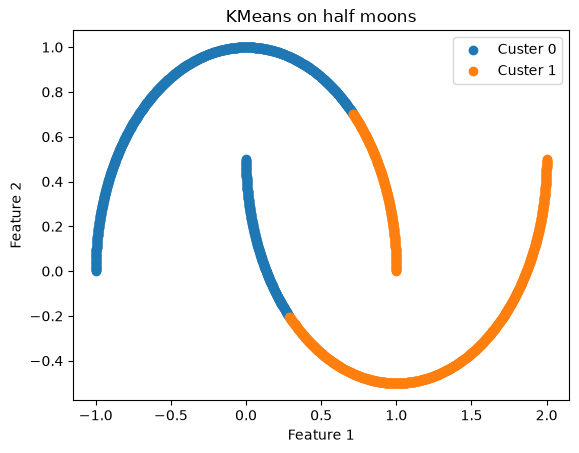

In [144]:
for i in range(2):
    plt.scatter(moons_X[km_labels == i, 0], moons_X[km_labels == i, 1], label=f"Custer {i}")
plt.title("KMeans on half moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [145]:
n_noise = (db_labels == -1).sum()
print(f"Noise points: {n_noise} out of {len(db_labels)}")

Noise points: 0 out of 2000


#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

eps=0.05: 2 clusters, 0 noise points
eps=0.1: 2 clusters, 0 noise points
eps=0.2: 2 clusters, 0 noise points
eps=0.3: 2 clusters, 0 noise points


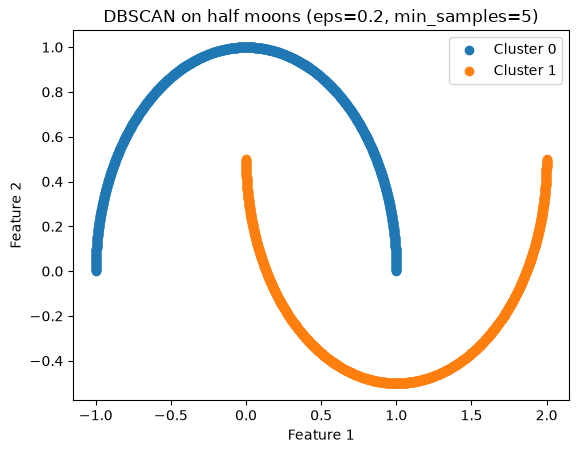

In [146]:
for eps in [0.05, 0.1, 0.2, 0.3]:
    labels = DBSCAN(eps = eps, min_samples= 5).fit_predict(moons_X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"eps={eps}: {n_clusters} clusters, {(labels == -1).sum()} noise points")

db = DBSCAN(eps=0.2, min_samples=5)
db_labels = db.fit_predict(moons_X)

for label in np.unique(db_labels):
    plt.scatter(moons_X[db_labels == label, 0], moons_X[db_labels == label, 1], label=f"Cluster {label}")

plt.title("DBSCAN on half moons (eps=0.2, min_samples=5)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

I tried eps values from 0.05 to 0.3 with min_samples = 5. All of them found exactly 2 clusters with no noise points, because the half-moon data has no added noise and the points are densly packed. So in that case i choose eps = 0.2 and min_samples = 5 as middle value

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

DBSCAN is better for this dataset. from the figures we can see that K-Means cuts the data with a straight line, so each cluster contains one moon and part of the other. That happens when K-Mean trying to assign each point to the nearest centre, so it can make round clusters. In the other hand DBSCAN points that are close to each other and form a continuos chain belong together - that lets it follow the curved shape of the moon. However DBSCAN can be very sensitive with eps and noise around the data, but since this dataset does not have any noise, so better is DBSCAN

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [147]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()
penguins.shape
penguins.info()
penguins.describe()
isnull = penguins.isnull().sum()
duplicated = penguins.duplicated().sum()
print("null values :\n", isnull)
print("there is :", duplicated, "duplicates")


<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB
null values :
 culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64
there is : 1 duplicates


The data set contains 344 rows per every column and there is 5 columns. culmen_lenght_mm, culmen_depth_mm, flipper_lenght_mm, body_mass_g - those are float64 type, sex is different here - string(text/categorical). This data set uses about 13.6 KB of memory. The numeric columns each have 343 non-values, so there 2 missing of each of them, and sex has 9 missing, so there is small ammount of missing data that needs handling

#### Based on dataframe describe, in own words explain any abnormal characteristics 

<Double-click here to add your answer. Ctrl+Shift to enter>

#### 14. Explore corrupted data

In [148]:
penguins.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


In describe(), flipper_lenght_mm and body_magg_g, min ; max values are far outsite the typical range, which looks like outlier or data error. The other columns look reasonable.

In [149]:
missing_rows = penguins[penguins.isnull().any(axis=1)]
print(missing_rows)
print("Shape:", missing_rows.shape)

     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex
3                 NaN              NaN                NaN          NaN  NaN
8                34.1             18.1              193.0       3475.0  NaN
10               37.8             17.1              186.0       3300.0  NaN
11               37.8             17.3              180.0       3700.0  NaN
47               37.5             18.9              179.0       2975.0  NaN
246              44.5             14.3              216.0       4100.0  NaN
286              46.2             14.4              214.0       4650.0  NaN
324              47.3             13.8              216.0       4725.0  NaN
339               NaN              NaN                NaN          NaN  NaN
Shape: (9, 5)


In [150]:
print(penguins['sex'].value_counts(dropna=False))

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64


In [151]:
print(penguins[~penguins['sex'].isin(['MALE', 'FEMALE']) & penguins['sex'].notnull()])

print(penguins.describe().loc[['min', 'max']])

     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g sex
336              44.5             15.7              217.0       4875.0   .
     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
min              32.1             13.1             -132.0       2700.0
max              59.6             21.5             5000.0       6300.0


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [152]:
penguins_clean = penguins.dropna()
penguins_clean = penguins_clean[penguins_clean['sex'].isin(['MALE', 'FEMALE'])]
penguins_clean = penguins_clean[(penguins_clean['flipper_length_mm'] > 100) & (penguins_clean['flipper_length_mm'] < 300)]
print(penguins_clean.shape)
penguins_clean.head()

(332, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [153]:
num_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
scaler = StandardScaler()
X_penguins = scaler.fit_transform(penguins_clean[num_cols])

X_check = pd.DataFrame(X_penguins, columns=num_cols)
X_check.isnull().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
dtype: int64

In [154]:
y_penguins = penguins_clean['sex']

Y_check = pd.DataFrame(y_penguins, columns=penguins_clean)
Y_check.isnull().sum()

(39.1, 18.7, 181.0, 3750.0, MALE)      0
(39.5, 17.4, 186.0, 3800.0, FEMALE)    0
(40.3, 18.0, 195.0, 3250.0, FEMALE)    0
(36.7, 19.3, 193.0, 3450.0, FEMALE)    0
(39.3, 20.6, 190.0, 3650.0, MALE)      0
                                      ..
(47.2, 13.7, 214.0, 4925.0, FEMALE)    0
(46.8, 14.3, 215.0, 4850.0, FEMALE)    0
(50.4, 15.7, 222.0, 5750.0, MALE)      0
(45.2, 14.8, 212.0, 5200.0, FEMALE)    0
(49.9, 16.1, 213.0, 5400.0, MALE)      0
Length: 332, dtype: int64

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

I removed all rows with missing values and also dropped rows with invalid sex values.

**PROS** 
It is simple, no values are invented, and PCA and scaling need complete data. There is 344 rows and after removal (about 10 affected) we lose very little.

**CONS**
We actually lose some real data, and if the missing values were not random, removing them could affect the datset. An alternative would be to fill missing numbers with mean or median, so that keeps something around values with no other distraction.

#### 16. Perform PCA with 2 components. Plot the results 

     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
min              32.1             13.1              172.0       2700.0
max              59.6             21.5              231.0       6300.0
Explained variance ratio: [0.68713344 0.19641564]


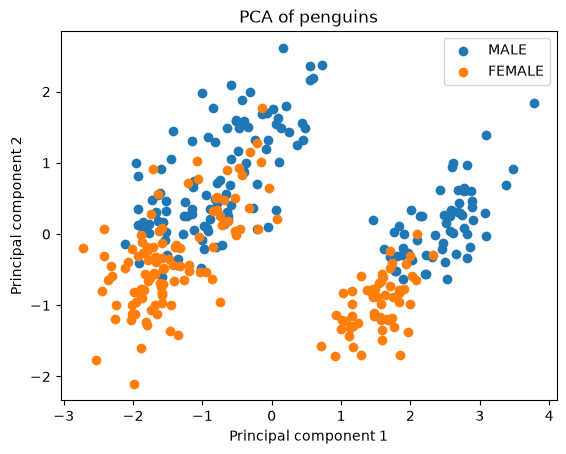

In [155]:
print(penguins_clean.describe().loc[['min', 'max']])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_penguins)

print("Explained variance ratio:", pca.explained_variance_ratio_)

for label in y_penguins.unique():
    mask = (y_penguins == label).values
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=label)

plt.title("PCA of penguins")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.legend()
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

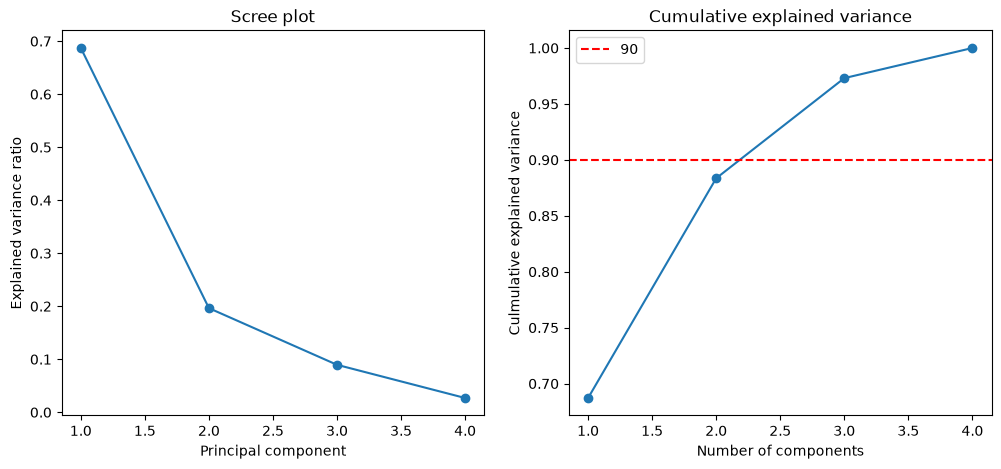

[0.68713344 0.88354908 0.9730663  1.        ]


In [156]:
pca_full = PCA()
pca_full.fit(X_penguins)

ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratio)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(range(1, len(ratio) + 1), ratio, marker='o')
axes[0].set_title("Scree plot")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")

axes[1].plot(range(1, len(cumulative) + 1), cumulative, marker='o')
axes[1].axhline(0.9, color='red', linestyle='--', label='90')
axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Culmulative explained variance")
axes[1].legend()

plt.show()
print(cumulative)

#### 18. Calculate (show in numbers) and display component loadings

In [157]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns = ['PC1', 'PC2'],
    index=num_cols
)
print(loadings)

                        PC1       PC2
culmen_length_mm   0.453174  0.604990
culmen_depth_mm   -0.398518  0.792959
flipper_length_mm  0.576880  0.003798
body_mass_g        0.550478  0.072032


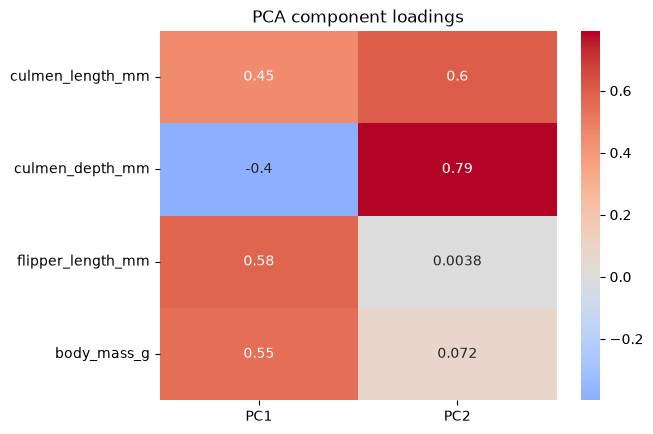

In [158]:
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0)
plt.title("PCA component loadings")
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [159]:
X_penguins_pca = X_pca

X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca, y_penguins, test_size = 0.2, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8208955223880597
              precision    recall  f1-score   support

      FEMALE       0.88      0.78      0.83        37
        MALE       0.76      0.87      0.81        30

    accuracy                           0.82        67
   macro avg       0.82      0.83      0.82        67
weighted avg       0.83      0.82      0.82        67

[[29  8]
 [ 4 26]]


#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [160]:
penguins_unknown = penguins[penguins['sex'].isnull()].copy()
penguins_unknown = penguins_unknown.dropna(subset=num_cols)
penguins_unknown = penguins_unknown[(penguins_unknown['flipper_length_mm'] > 100 & (penguins_unknown['flipper_length_mm'] < 300))]

X_unknown_scaled = scaler.transform(penguins_unknown[num_cols])

In [161]:
X_unknown_pca = pca.transform(X_unknown_scaled)

In [162]:
X_train = X_pca
y_train = y_penguins

clf = LogisticRegression()
clf.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [163]:
predictions = clf.predict(X_unknown_pca)

result = penguins_unknown.copy()
result['predict_sex'] = predictions
print(result)

     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex  \
8                34.1             18.1              193.0       3475.0  NaN   
10               37.8             17.1              186.0       3300.0  NaN   
11               37.8             17.3              180.0       3700.0  NaN   
47               37.5             18.9              179.0       2975.0  NaN   
246              44.5             14.3              216.0       4100.0  NaN   
286              46.2             14.4              214.0       4650.0  NaN   
324              47.3             13.8              216.0       4725.0  NaN   

    predict_sex  
8        FEMALE  
10       FEMALE  
11       FEMALE  
47       FEMALE  
246      FEMALE  
286      FEMALE  
324      FEMALE  
